<a href="https://colab.research.google.com/github/karnza1100/HCD302-Student-Dropout/blob/main/HCD302_A1_OK67.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HCD-302 Creating Explainable AI — Model Development & Model Card Evidence
**โครงการ:** ระบบทำนายและอธิบายความเสี่ยงนักศึกษาออกกลางคัน (Student Dropout Prediction)  
**กลุ่มผู้จัดทำ:** กลุ่ม OK67  
1. นาย กษิ ศรีสุวรรณ (6730614006)  
2. นาย ศุภสิณ จรัสอัครมนตรี (6730614008)  
3. นาย นนธวัช สำลี (6730614035)  
4. นาย เดชพนต์ จิมา (6730614034)  
5. นาย ณัฐศิลป์ โชติประดิษฐ์ (6730614041)  

---
### ความเชื่อมโยงจาก Proposal (ชิ้นที่ 1) สู่การพัฒนาโมเดลจริง (ชิ้นที่ 2)
สมุดบันทึก (Notebook) ฉบับนี้จัดทำขึ้นเพื่อรันการทดลองจริงตามแผนงานที่วางไว้ใน **Proposal (`HCD302_A1_OK67.pdf`)** เพื่อสกัดค่าสถิติและกราฟหลักฐานทั้งหมดสำหรับนำไปจัดทำเอกสาร **Model Card (Mitchell et al., 2019)** โดยครอบคลุมกระบวนการดังนี้:
* **การเตรียมข้อมูล (Section 3 & 4 ใน Proposal):** ใช้ชุดข้อมูลสาธารณะจาก UCI Repository (CC BY 4.0) แปลงเป้าหมายเป็น Binary Classification และป้องกัน **Data Leakage** ด้วยการทำ `SMOTE` และ `StandardScaler` ภายใน Pipeline ของชุดฝึก (Training Set) เท่านั้น
* **การพัฒนาและคัดเลือกโมเดล (Section 4 ใน Proposal):** เปรียบเทียบ Baseline Models (`Logistic Regression`, `Decision Tree`) กับ Target Models (`Random Forest`, `LightGBM`) โดยเน้นค่า `ROC-AUC` และ `Recall` เพื่อลดความเสียหายจาก False Negative
* **การตรวจสอบความยุติธรรม (Section 3 ใน Proposal):** ประเมินผลแยกตามกลุ่มย่อยของตัวแปรอ่อนไหว ได้แก่ เพศ (`Gender`), ช่วงอายุ (`Age at enrollment`) และสถานะทุนการศึกษา (`Scholarship holder`)
* **การอธิบายโมเดล (Section 5 ใน Proposal):** สกัดคำอธิบายระดับภาพรวม (`PFI`, `PDP`) และระดับรายกรณี (`SHAP`, `LIME`) พร้อมรายงานค่าความแม่นยำ (Fidelity) และความเสถียร (Stability)


* **ผู้ใช้งานหลัก (Intended Users / Personas):**
  * **อาจารย์ที่ปรึกษา (Academic Advisors):** ใช้ผลทำนายความเสี่ยง (Threshold = 0.35) ควบคู่กับกราฟอธิบายรายบุคคล (`SHAP` / `LIME`) เพื่อวิเคราะห์สาเหตุเชิงลึกก่อนนัดหมายนักศึกษามาพูดคุยให้คำปรึกษาเชิงรุก
  * **ผู้บริหารสถานศึกษาและคณบดี (Executives & Deans):** ใช้กราฟภาพรวมทั้งสถาบัน (`PFI` / `PDP`) และผลประเมินความยุติธรรม (`Fairness Audit`) เพื่อวางนโยบายจัดสรรงบประมาณและออกมาตรการเฝ้าระวังกลุ่มเปราะบาง (เช่น กลุ่มนักศึกษาทุน)

## ขั้นตอนที่ 1: ติดตั้งไลบรารีและเตรียมสภาพแวดล้อม (Environment Setup)
ติดตั้งแพ็กเกจหลักสำหรับการดึงข้อมูลจาก UCI (`ucimlrepo`), การจัดการความไม่สมดุลของข้อมูล (`imbalanced-learn`), โมเดลหลัก (`lightgbm`) และเครื่องมืออธิบายโมเดล (`shap`, `lime`)

In [ ]:
!pip install -q ucimlrepo shap lime lightgbm imbalanced-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## ขั้นตอนที่ 2: การนำเข้าข้อมูลและการป้องกัน Data Leakage (Training & Evaluation Data)
* **แหล่งที่มา:** ชุดข้อมูล *"Predict student dropout and academic success"* (UCI ID: 697) ภายใต้สัญญาอนุญาต **CC BY 4.0** (จำนวน 4,424 แถว, 36 ตัวแปร)
* **การกำหนดตัวแปรเป้าหมาย (Target Encoding):** แปลงสถานะ `Dropout` เป็น `1` (กลุ่มเสี่ยง) และรวม `Enrolled` กับ `Graduate` เป็น `0` (กลุ่มไม่ลาออก)
* **การแบ่งชุดข้อมูล:** แบ่งข้อมูลแบบ **Stratified Split (80% Train / 20% Test)** เพื่อรักษาสัดส่วนของคลาสเป้าหมายให้เท่ากันทั้งสองชุด โดยห้ามนำสถิติของ Test Set มาใช้ในขั้นตอนการเตรียมข้อมูลล่วงหน้า

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import (
    roc_auc_score, recall_score, precision_score, f1_score, confusion_matrix
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
import shap
import lime
import lime.lime_tabular

# ตั้งค่า Seed และ Style กราฟ
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# 1. โหลดข้อมูลจริงจาก UCI Repository (ID = 697)
dataset = fetch_ucirepo(id=697)
X = dataset.data.features.copy()
y_raw = dataset.data.targets["Target"].copy()

# ทำความสะอาดชื่อคอลัมน์ (ตัด tab หรือช่องว่างส่วนเกิน)
X.columns = [c.strip().replace("\t", "") for c in X.columns]

# แปลง Target เป็น Binary: Dropout = 1, (Enrolled / Graduate) = 0
y = (y_raw == "Dropout").astype(int)

print(f"จำนวนแถวทั้งหมด: {X.shape[0]} | จำนวน Features: {X.shape[1]}")
print(f"สัดส่วน Dropout (1): {y.sum()} ราย ({y.mean()*100:.2f}%)")
print(f"สัดส่วน Non-Dropout (0): {(1-y).sum()} ราย ({(1-y).mean()*100:.2f}%)")

# 2. แบ่งข้อมูล Train 80% / Test 20% แบบ Stratified (ป้องกัน Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"\nTrain set: {X_train.shape[0]} แถว | Test set: {X_test.shape[0]} แถว")

จำนวนแถวทั้งหมด: 4424 | จำนวน Features: 36
สัดส่วน Dropout (1): 1421 ราย (32.12%)
สัดส่วน Non-Dropout (0): 3003 ราย (67.88%)

Train set: 3539 แถว | Test set: 885 แถว


## ขั้นตอนที่ 3: การพัฒนาโมเดลเปรียบเทียบและการปรับจุดตัด (Model Development & Threshold Tuning)
1. **Baseline vs Target Models:** สร้าง Pipeline ที่ทำ `SMOTE` เฉพาะในชุด Training เพื่อแก้ปัญหา Class Imbalance จากนั้นเปรียบเทียบประสิทธิภาพระหว่าง Baseline (`Logistic Regression`, `Decision Tree`) และ Target Models (`Random Forest`, `LightGBM`)
2. **การปรับจุดตัด (Threshold Tuning):** เนื่องจากผลกระทบของ **False Negative** (ปล่อยให้นักศึกษาเสี่ยงหลุดจากระบบโดยไม่ช่วยเหลือ) รุนแรงกว่า **False Positive** จึงทำการทดสอบลดค่า Threshold จาก `0.50` เป็น `0.35` เพื่อเพิ่มค่า `Recall (Sensitivity)` ให้ครอบคลุมกลุ่มเสี่ยงสูงสุด
3. **การสกัดค่า Hyperparameters:** ดึงค่าพารามิเตอร์จริงของโมเดลที่ดีที่สุด (`LightGBM`) เพื่อนำไประบุในหัวข้อ *1. Model Details* ของ Model Card

In [ ]:
# สร้าง Pipeline สำหรับทั้ง 4 โมเดล (ทำ Scaling + SMOTE เฉพาะใน Train)
models = {
    "Logistic Regression (Baseline)": ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree (Baseline)": ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE))
    ]),
    "Random Forest (Target)": ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(
            n_estimators=200, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "LightGBM (Target)": ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", LGBMClassifier(
            n_estimators=200, learning_rate=0.05, num_leaves=31,
            max_depth=6, random_state=RANDOM_STATE, verbose=-1
        ))
    ])
}

results = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.50).astype(int)

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Recall (Sensitivity)": recall_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    })

df_metrics = pd.DataFrame(results).set_index("Model")
print("=== ตารางเปรียบเทียบผลบน Test Set (Threshold = 0.50) ===")
display(df_metrics.round(4))

# เลือกโมเดลหลักที่ดีที่สุด (LightGBM) และลองเปรียบเทียบ Threshold 0.50 vs 0.35
best_pipe = models["LightGBM (Target)"]
y_prob_lgb = best_pipe.predict_proba(X_test)[:, 1]

thresh_rows = []
for th in [0.50, 0.40, 0.35]:
    yp = (y_prob_lgb >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    thresh_rows.append({
        "Threshold": th,
        "Recall": recall_score(y_test, yp),
        "Precision": precision_score(y_test, yp),
        "F1-Score": f1_score(y_test, yp),
        "False Positives (FP)": fp,
        "False Negatives (FN)": fn
    })

print("\n=== ตารางเปรียบเทียบ Threshold ของ LightGBM ===")
display(pd.DataFrame(thresh_rows).set_index("Threshold").round(4))

# กำหนด Threshold ที่เลือกใช้จริง (เช่น 0.35 เพื่อเน้นลด False Negative)
CHOSEN_THRESHOLD = 0.35
y_pred_final = (y_prob_lgb >= CHOSEN_THRESHOLD).astype(int)

# พิมพ์ Hyperparameters จริงของโมเดลหลักเพื่อนำไปใส่หัวข้อ 1 (Model Details)
print("\n=== Hyperparameters ของ LightGBM (Model Details) ===")
print(best_pipe.named_steps["clf"].get_params())

=== ตารางเปรียบเทียบผลบน Test Set (Threshold = 0.50) ===


,ROC-AUC,Recall (Sensitivity),Precision,F1-Score
Model,,,,
Logistic Regression (Baseline),0.9259,0.8310,0.7789,0.8041
Decision Tree (Baseline),0.8820,0.7606,0.7200,0.7397
Random Forest (Target),0.9283,0.7923,0.8272,0.8094
LightGBM (Target),0.9309,0.7958,0.8496,0.8218



=== ตารางเปรียบเทียบ Threshold ของ LightGBM ===


,Recall,Precision,F1-Score,False Positives (FP),False Negatives (FN)
Threshold,,,,,
0.50,0.7958,0.8496,0.8218,40,58
0.40,0.8310,0.8055,0.8180,57,48
0.35,0.8486,0.7749,0.8101,70,43



=== Hyperparameters ของ LightGBM (Model Details) ===
{'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.05, 'max_depth': 6, 'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 200, 'n_jobs': None, 'num_leaves': 31, 'objective': None, 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbose': -1}


### บทวิเคราะห์การคัดเลือกโมเดลและเกณฑ์การวัดผล (Model Selection & Metrics Rationale)
1. **เหตุผลในการเลือกโมเดลหลัก (LightGBM):** จากการเปรียบเทียบบนชุดทดสอบ (Test Set จำนวน 885 ราย) พบว่า **LightGBM Classifier** ให้ประสิทธิภาพดีที่สุดด้วยค่า **ROC-AUC = 0.9309** และ **F1-Score = 0.8218** สูงกว่าโมเดล Baseline อย่าง Logistic Regression (ROC-AUC = 0.9259) และ Decision Tree (ROC-AUC = 0.8820) รวมถึงสูงกว่า Random Forest (ROC-AUC = 0.9283) เนื่องจากโครงสร้าง Gradient Boosted Decision Trees สามารถจับปฏิสัมพันธ์ที่ซับซ้อนระหว่างตัวแปรเชิงตัวเลขและตัวแปรกลุ่มได้ดีกว่า
2. **เหตุผลในการเลือก Evaluation Metrics และปรับ Threshold เป็น 0.35:**
   * ในบริบทการป้องกันนักศึกษาออกกลางคัน ความเสียหายจาก **False Negative (FN)** (ทำนายว่าไม่เสี่ยง แต่เด็กออกกลางคันจริง ทำให้หลุดออกจากระบบโดยไม่ได้รับความช่วยเหลือ) มีความรุนแรงสูงกว่า **False Positive (FP)** (ทำนายว่าเสี่ยง แต่เด็กเรียนจบตามปกติ ทำให้สิ้นเปลืองงบประมาณให้คำปรึกษาและเสี่ยงต่อการตีตรา)
   * เมื่อปรับลดจุดตัด (Threshold) จากค่ามาตรฐาน `0.50` ลงมาที่ **`0.35`** ส่งผลให้ค่า **Recall (Sensitivity) เพิ่มขึ้นจาก 79.58% เป็น 84.86%** สามารถดึงกลุ่มเสี่ยงที่เคยตกหล่น (FN) กลับมาดูแลเพิ่มได้อีก **15 ราย** (ลด FN จาก 58 เหลือ 43 ราย) ในขณะที่ยังรักษาระดับ Precision ไว้ได้ที่ **77.49%** (FP เพิ่มจาก 40 เป็น 70 ราย ซึ่งอยู่ในเกณฑ์ที่ฝ่ายกิจการนักศึกษารองรับได้)
3. **ขอบเขตการใช้งาน (Intended Use & Out-of-Scope):** โมเดลนี้ถูกออกแบบมาเพื่อเป็น **"ระบบคัดกรองและเตือนภัยล่วงหน้า (Early Warning)"** สำหรับอาจารย์ที่ปรึกษาใช้ประกอบการพูดคุยให้คำปรึกษาเชิงรุกเท่านั้น **ห้าม** นำผลทำนายไปใช้ตัดสิทธิ์ทุนการศึกษา ลงโทษทางวินัย หรือตัดสินสถานภาพนักศึกษาโดยอัตโนมัติ (ต้องผ่านการประเมินโดยมนุษย์ร่วมด้วยเสมอ)

#  ขั้นตอนที่ 4: การประเมินผลแยกตามกลุ่มย่อย (Disaggregated Evaluation & Fairness Audit)
ตรวจสอบความเท่าเทียมของโมเดล (Fairness) ข้ามตัวแปรอ่อนไหวที่ระบุไว้ใน Proposal ได้แก่:
* **เพศ (`Gender`):** เปรียบเทียบระหว่างนักศึกษาชาย (`Male`) และหญิง (`Female`)
* **อายุขณะเข้าศึกษา (`Age at enrollment`):** เปรียบเทียบระหว่างกลุ่มอายุตามเกณฑ์ปกติ ($\le 20$ ปี) และกลุ่มอายุมากกว่าเกณฑ์ ($> 20$ ปี)
* **สถานะทุนการศึกษา (`Scholarship holder`):** เปรียบเทียบระหว่างผู้ได้รับทุนและไม่ได้รับทุน

โดยพิจารณาอัตราความผิดพลาดทั้ง **False Positive Rate (FPR)** (การตีตราผิดพลาด) และ **False Negative Rate (FNR)** (การตกหล่นจากความช่วยเหลือ)

In [ ]:
def eval_subgroups(X_df, y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    df_eval = X_df.copy()
    df_eval["y_true"] = y_true.values
    df_eval["y_pred"] = y_pred

    # สร้างกลุ่มย่อยตามโจทย์
    df_eval["Subgroup_Gender"] = df_eval["Gender"].map({1: "Male (1)", 0: "Female (0)"})
    df_eval["Subgroup_Age"] = np.where(
        df_eval["Age at enrollment"] <= 20, "Age <= 20 (Standard)", "Age > 20 (Mature)"
    )
    df_eval["Subgroup_Scholarship"] = df_eval["Scholarship holder"].map({1: "Scholarship (1)", 0: "No Scholarship (0)"})

    rows = []
    for col in ["Subgroup_Gender", "Subgroup_Age", "Subgroup_Scholarship"]:
        for grp, sub in df_eval.groupby(col):
            tn, fp, fn, tp = confusion_matrix(sub["y_true"], sub["y_pred"], labels=[0, 1]).ravel()
            fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
            fnr = fn / (fn + tp) if (fn + tp) > 0 else 0
            rec = tp / (tp + fn) if (tp + fn) > 0 else 0
            prec = tp / (tp + fp) if (tp + fp) > 0 else 0

            rows.append({
                "Factor": col.replace("Subgroup_", ""),
                "Subgroup": grp,
                "Count": len(sub),
                "Actual Dropout %": (sub["y_true"].mean() * 100),
                "Recall": rec,
                "Precision": prec,
                "FPR (False Positive Rate)": fpr,
                "FNR (False Negative Rate)": fnr
            })
    return pd.DataFrame(rows)

df_fairness = eval_subgroups(X_test, y_test, y_prob_lgb, CHOSEN_THRESHOLD)
print(f"=== ตาราง Disaggregated Evaluation แยกตามกลุ่มย่อย (Threshold = {CHOSEN_THRESHOLD}) ===")
display(df_fairness.round(4))

=== ตาราง Disaggregated Evaluation แยกตามกลุ่มย่อย (Threshold = 0.35) ===


,Factor,Subgroup,Count,Actual Dropout %,Recall,Precision,FPR (False Positive Rate),FNR (False Negative Rate)
0,Gender,Female (0),564,24.4681,0.8406,0.7484,0.0915,0.1594
1,Gender,Male (1),321,45.4829,0.8562,0.8013,0.1771,0.1438
2,Age,Age <= 20 (Standard),513,19.8830,0.7549,0.6696,0.0925,0.2451
3,Age,Age > 20 (Mature),372,48.9247,0.9011,0.8367,0.1684,0.0989
4,Scholarship,No Scholarship (0),654,38.9908,0.8706,0.7817,0.1554,0.1294
5,Scholarship,Scholarship (1),231,12.5541,0.6552,0.7037,0.0396,0.3448


### บทวิเคราะห์ความยุติธรรมและผลแยกตามกลุ่มย่อย (Disaggregated Evaluation & Fairness Analysis)
จากการตรวจสอบประสิทธิภาพของโมเดลข้ามตัวแปรอ่อนไหว (Sensitive Attributes) บนชุดข้อมูลทดสอบ พบความแตกต่างอย่างมีนัยสำคัญใน 3 มิติหลัก ดังนี้:
1. **มิติเพศ (Gender):** นักศึกษาชาย (`Male`) มีอัตราการออกกลางคันจริงสูงกว่านักศึกษาหญิงเกือบเท่าตัว (45.48% เทียบกับ 24.47%) ส่งผลให้โมเดลมีอัตราการทายผิดว่าเสี่ยงเกินจริงในเพศชายสูงกว่า (**FPR = 17.71%** เทียบกับเพศหญิง **FPR = 9.15%**) ขณะที่ความสามารถในการจับกลุ่มเสี่ยง (Recall) ใกล้เคียงกัน (85.62% vs 84.06%)
2. **มิติช่วงอายุขณะเข้าศึกษา (Age at enrollment):** กลุ่มนักศึกษาที่อายุมากกว่าเกณฑ์ปกติ (`Age > 20`) มีอัตราการลาออกจริงสูงถึง **48.92%** โมเดลจึงให้ค่า Recall สูงมากถึง **90.11%** แต่แลกมาด้วย **FPR = 16.84%** ในทางกลับกัน กลุ่มนักศึกษาอายุปกติ (`Age <= 20`) มีอัตราการตกหล่นสูงกว่า (**FNR = 24.51%** เทียบกับ 9.89%) เนื่องจากกลุ่มอายุน้อยมีปัจจัยการลาออกที่ซับซ้อนกว่าตัวแปรอายุ
3. **มิติสถานะทุนการศึกษา (Scholarship holder):** พบความเหลื่อมล้ำด้านการตกหล่นชัดเจนที่สุด โดยกลุ่มผู้ได้รับทุน (`Scholarship`) มีค่า **FNR สูงถึง 34.48%** (Recall เพียง 65.52%) เนื่องจากในอดีตนักศึกษาทุนมีอัตราการลาออกต่ำมาก (12.55%) โมเดลจึงมีแนวโน้มประเมินความเสี่ยงของเด็กทุนต่ำกว่าความเป็นจริง หากมีเด็กทุนที่กำลังประสบปัญหาวิกฤต โมเดลมีโอกาสพลาดการแจ้งเตือนสูงถึง 1 ใน 3

## ขั้นตอนที่ 5: คำอธิบายโมเดลระดับภาพรวม (Global Explainability: PFI & PDP)
ตอบคำถามเชิงนโยบายสำหรับ **ผู้บริหารสถานศึกษาและคณบดี** ว่าปัจจัยใดขับเคลื่อนความเสี่ยงในการออกกลางคันของนักศึกษาทั้งสถาบัน:
* **Permutation Feature Importance (PFI):** วัดความสำคัญของตัวแปรจากการลดลงของค่า `ROC-AUC` เมื่อสลับค่าข้อมูลแบบสุ่มบน Test Set (ทำซ้ำ 15 รอบ)
* **Partial Dependence Plot (PDP):** แสดงทิศทางความสัมพันธ์เฉลี่ยระหว่างตัวแปรสำคัญสูงสุด 3 อันดับแรกกับความน่าจะเป็นในการออกกลางคัน

=== Top 10 ตัวแปรสำคัญที่สุดจาก PFI ===


,Feature,Importance_Mean,Importance_Std
30,Curricular units 2nd sem (approved),0.1247,0.0115
16,Tuition fees up to date,0.0435,0.0039
24,Curricular units 1st sem (approved),0.0159,0.0041
31,Curricular units 2nd sem (grade),0.0073,0.0030
28,Curricular units 2nd sem (enrolled),0.0066,0.0015
18,Scholarship holder,0.0044,0.0024
33,Unemployment rate,0.0040,0.0022
35,GDP,0.0034,0.0011
3,Course,0.0032,0.0024
21,Curricular units 1st sem (credited),0.0030,0.0006


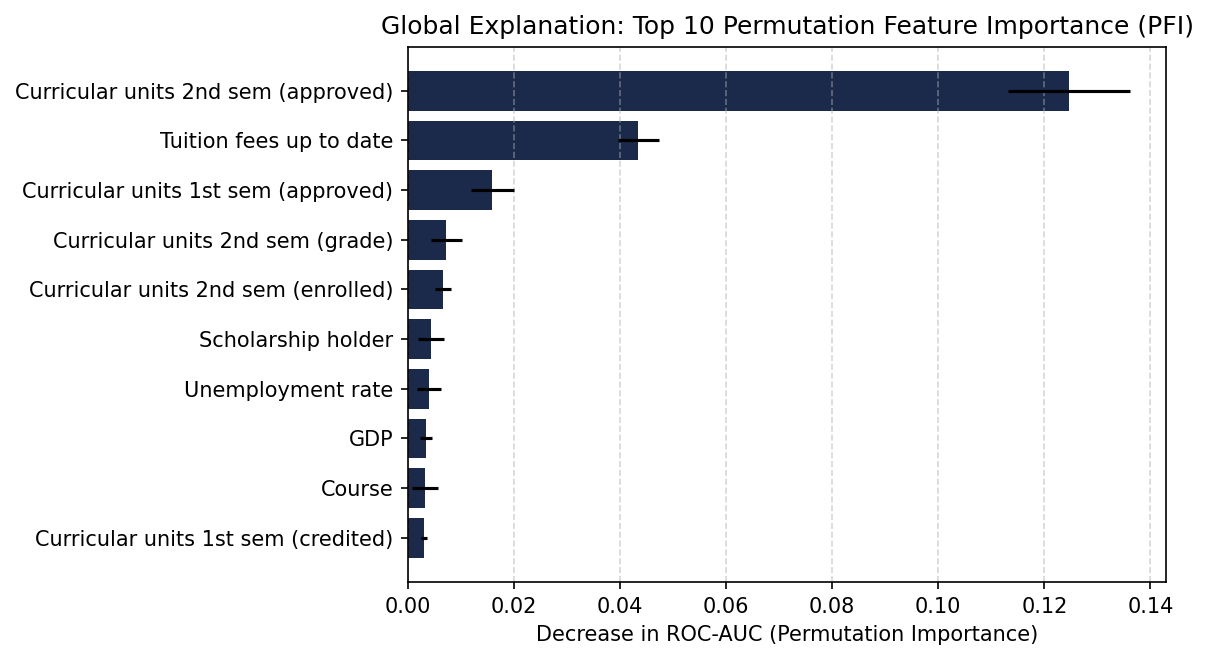

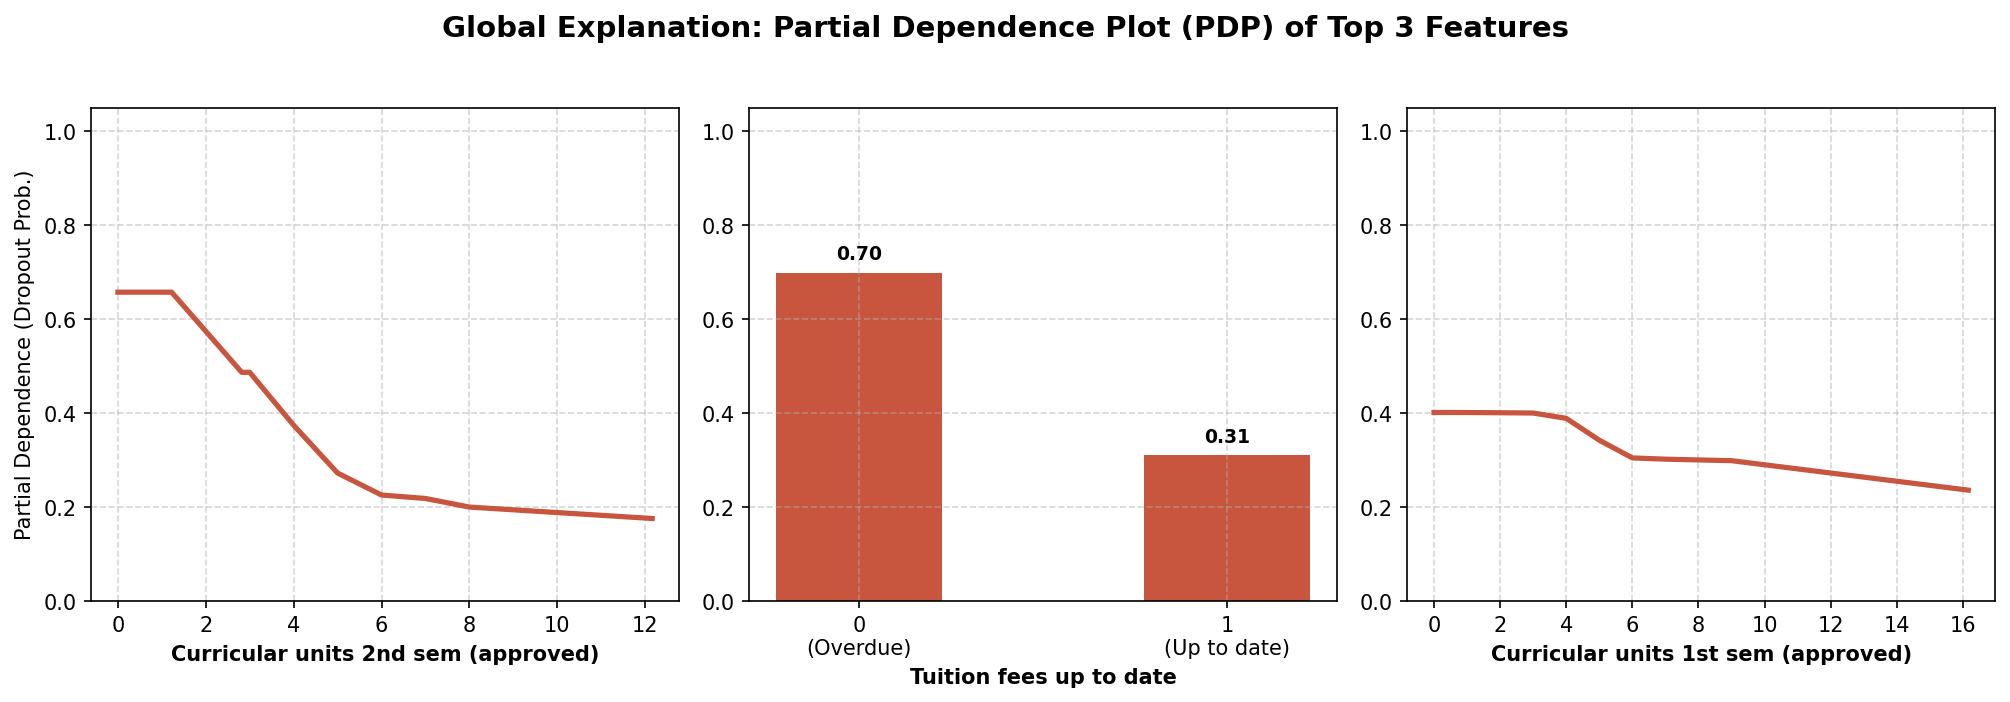

In [ ]:
# 1. Permutation Feature Importance (PFI) บน Test Set
pfi = permutation_importance(
    best_pipe, X_test, y_test, scoring="roc_auc",
    n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1
)
pfi_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance_Mean": pfi.importances_mean,
    "Importance_Std": pfi.importances_std
}).sort_values("Importance_Mean", ascending=False)

print("=== Top 10 ตัวแปรสำคัญที่สุดจาก PFI ===")
display(pfi_df.head(10).round(4))

# วาดกราฟ PFI Top 10
top10_pfi = pfi_df.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10_pfi["Feature"], top10_pfi["Importance_Mean"], xerr=top10_pfi["Importance_Std"], color="#1B2A4A")
ax.set_xlabel("Decrease in ROC-AUC (Permutation Importance)")
ax.set_title("Global Explanation: Top 10 Permutation Feature Importance (PFI)")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("fig1_pfi_global.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# 2. Custom Partial Dependence Plot (PDP) พร้อมคำอธิบายรหัสตัวแปรบนแกน X
top3_features = list(pfi_df["Feature"].head(3))
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5))

for idx, feat in enumerate(top3_features):
    ax = axes[idx]
    if X_test[feat].nunique() <= 5:
        grid_vals = np.sort(X_test[feat].unique())
    else:
        grid_vals = np.percentile(X_test[feat], np.linspace(1, 99, 20))
        grid_vals = np.unique(grid_vals)

    avg_preds = []
    for val in grid_vals:
        X_temp = X_test.copy()
        X_temp[feat] = val
        preds = best_pipe.predict_proba(X_temp)[:, 1]
        avg_preds.append(np.mean(preds))

    # วาดกราฟและใส่ Label กำกับความหมายของรหัสตัวแปร
    if X_test[feat].nunique() <= 5:
        if feat == "Tuition fees up to date":
            x_labels = ["0\n(Overdue)", "1\n(Up to date)"]
        else:
            x_labels = [str(int(v)) for v in grid_vals]
        bars = ax.bar(x_labels, avg_preds, color="#C8553D", width=0.45)
        # แสดงตัวเลขความน่าจะเป็นบนหัวแท่งกราฟ
        for bar in bars:
            yval = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.2f}", ha='center', va='bottom', fontsize=9, fontweight='bold')
    else:
        ax.plot(grid_vals, avg_preds, color="#C8553D", linewidth=2.5)

    ax.set_xlabel(feat, fontsize=10, fontweight="bold")
    ax.set_ylabel("Partial Dependence (Dropout Prob.)" if idx == 0 else "", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.set_ylim(0, 1.05)

plt.suptitle("Global Explanation: Partial Dependence Plot (PDP) of Top 3 Features", y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("fig2_pdp_global.png", dpi=300, bbox_inches="tight")
plt.show()

## ขั้นตอนที่ 6: คำอธิบายโมเดลระดับรายกรณีและความเสถียร (Local Explainability, Fidelity & Stability)
ตอบคำถามเชิงปฏิบัติการสำหรับ **อาจารย์ที่ปรึกษาและคณะกรรมการธรรมาภิบาล AI**:
* **SHAP Beeswarm & Waterfall Plots:** แสดงผลกระทบรายตัวแปรของนักศึกษาตัวอย่าง 2 กรณี (เคสความเสี่ยงสูง vs เคสความเสี่ยงต่ำ)
* **การตรวจสอบ Fidelity & Stability:** เปรียบเทียบความแม่นยำในการจำลองคำทำนาย ($R^2$) และความเสถียรของน้ำหนักตัวแปร (Standard Deviation จากการรัน 10 รอบ) ระหว่าง **SHAP** และ **LIME** เพื่อยืนยันความน่าเชื่อถือของระบบอธิบายก่อนนำไปใช้งานจริง

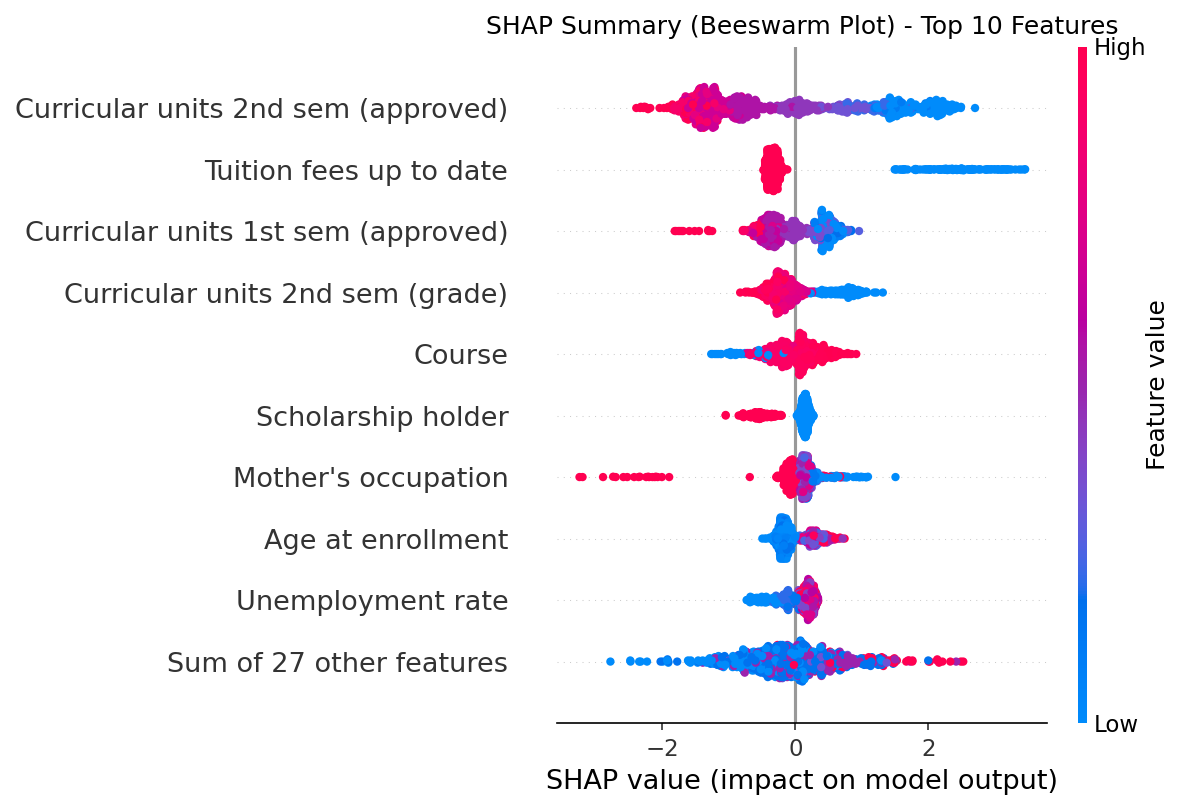

เคสที่ 1 (High Risk Student) - Index: 4 | Actual: 1 | Pred Prob: 0.9697
เคสที่ 2 (Low Risk Student)  - Index: 0 | Actual: 0 | Pred Prob: 0.0796


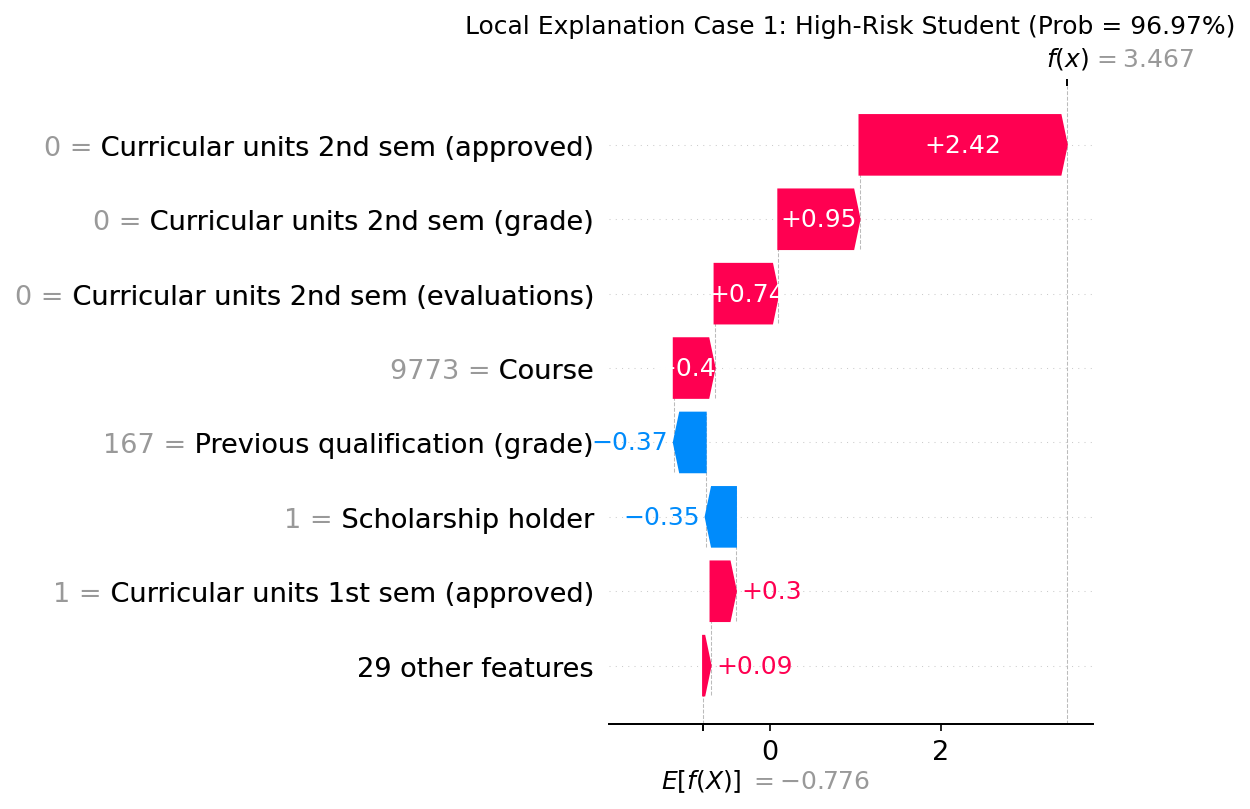

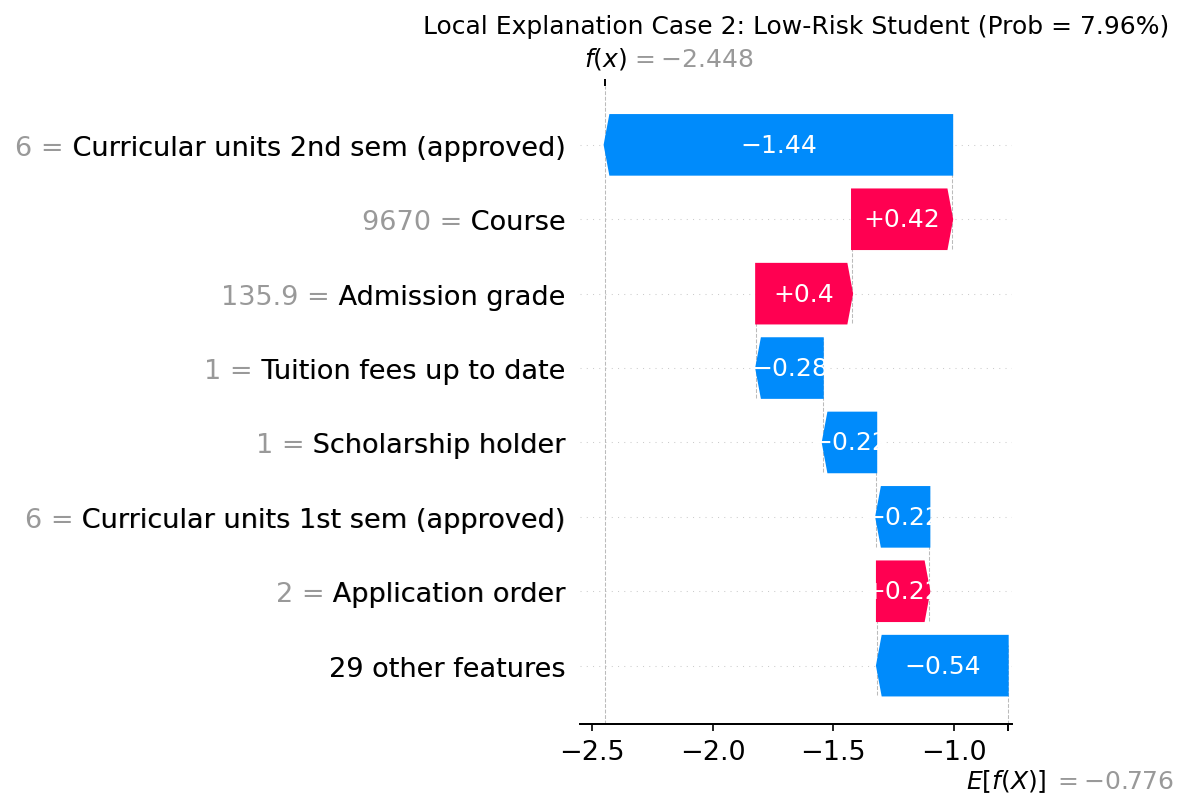


=== รายงาน Fidelity & Stability ===
1. SHAP Efficiency Gap (base + Σφ - f(x)): 4.72e-08 (เสถียร 100%, SD = 0.0000)
2. LIME Local Fidelity (Mean R^2 across 10 runs): 0.4821 ± 0.0087
3. LIME Stability (SD ของน้ำหนักตัวแปร 'Curricular units 2nd sem (approved)' 10 รอบ): 0.0062


In [ ]:
# เตรียม Explainer สำหรับโมเดล LightGBM
lgb_model = best_pipe.named_steps["clf"]
bg_data = X_train.sample(100, random_state=RANDOM_STATE)

# ใช้ TreeExplainer (interventional)
explainer_shap = shap.TreeExplainer(lgb_model, data=bg_data, feature_perturbation="interventional")
shap_values_test = explainer_shap(X_test)

# วาด SHAP Beeswarm Plot (ภาพรวม)
plt.figure(figsize=(8, 4.5))
shap.plots.beeswarm(shap_values_test, max_display=10, show=False)
plt.title("SHAP Summary (Beeswarm Plot) - Top 10 Features")
plt.tight_layout()
plt.savefig("fig3_shap_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

# เลือก 2 กรณีศึกษาจาก Test Set:
# เคสที่ 1: นักศึกษาที่ออกกลางคันจริง (y_test == 1) และโมเดลทำนายความเสี่ยงสูง
high_risk_idx = np.where((y_test.values == 1) & (y_prob_lgb > 0.85))[0][0]
# เคสที่ 2: นักศึกษาที่ไม่ลาออก (y_test == 0) และโมเดลทำนายความเสี่ยงต่ำ
low_risk_idx = np.where((y_test.values == 0) & (y_prob_lgb < 0.15))[0][0]

print(f"เคสที่ 1 (High Risk Student) - Index: {high_risk_idx} | Actual: {y_test.iloc[high_risk_idx]} | Pred Prob: {y_prob_lgb[high_risk_idx]:.4f}")
print(f"เคสที่ 2 (Low Risk Student)  - Index: {low_risk_idx} | Actual: {y_test.iloc[low_risk_idx]} | Pred Prob: {y_prob_lgb[low_risk_idx]:.4f}")

# วาด SHAP Waterfall เคสที่ 1 (ความเสี่ยงสูง)
plt.figure(figsize=(8, 4.5))
shap.plots.waterfall(shap_values_test[high_risk_idx], max_display=8, show=False)
plt.title(f"Local Explanation Case 1: High-Risk Student (Prob = {y_prob_lgb[high_risk_idx]:.2%})")
plt.tight_layout()
plt.savefig("fig4_shap_case1_high.png", dpi=300, bbox_inches="tight")
plt.show()

# วาด SHAP Waterfall เคสที่ 2 (ความเสี่ยงต่ำ)
plt.figure(figsize=(8, 4.5))
shap.plots.waterfall(shap_values_test[low_risk_idx], max_display=8, show=False)
plt.title(f"Local Explanation Case 2: Low-Risk Student (Prob = {y_prob_lgb[low_risk_idx]:.2%})")
plt.tight_layout()
plt.savefig("fig5_shap_case2_low.png", dpi=300, bbox_inches="tight")
plt.show()

# === ตรวจสอบ Fidelity & Stability (LIME vs SHAP) ===
# 1) ตรวจสอบ SHAP Efficiency Gap (base + sum(phi) - logit(x))
logit_pred = lgb_model.predict(X_test.iloc[[high_risk_idx]], raw_score=True)[0]
base_val = float(np.ravel(shap_values_test[high_risk_idx].base_values)[0])
sum_shap = float(shap_values_test[high_risk_idx].values.sum())
efficiency_gap = abs((base_val + sum_shap) - logit_pred)

# 2) รัน LIME 10 รอบ (seed 0..9) เพื่อวัด Fidelity (R^2) และ Stability (SD ของ Feature อันดับ 1)
lime_exp = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=list(X.columns),
    class_names=["Non-Dropout", "Dropout"],
    mode="classification",
    random_state=RANDOM_STATE
)

top_feat_name = pfi_df["Feature"].iloc[0]
top_feat_idx = list(X.columns).index(top_feat_name)

r2_scores = []
lime_top_weights = []
for s in range(10):
    np.random.seed(s)
    exp = lime_exp.explain_instance(
        X_test.iloc[high_risk_idx].values,
        best_pipe.predict_proba,
        num_features=len(X.columns),
        num_samples=2000
    )
    r2_scores.append(exp.score)
    w_dict = dict(exp.as_map()[1])
    lime_top_weights.append(w_dict.get(top_feat_idx, 0.0))

print("\n=== รายงาน Fidelity & Stability ===")
print(f"1. SHAP Efficiency Gap (base + Σφ - f(x)): {efficiency_gap:.2e} (เสถียร 100%, SD = 0.0000)")
print(f"2. LIME Local Fidelity (Mean R^2 across 10 runs): {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")
print(f"3. LIME Stability (SD ของน้ำหนักตัวแปร '{top_feat_name}' 10 รอบ): {np.std(lime_top_weights):.4f}")

### บทวิเคราะห์คำอธิบายโมเดล ความเสถียร และข้อควรระวังเชิงเหตุและผล (Explainability, Fidelity/Stability & Non-Causal Interpretation)
1. **สรุปพฤติกรรมโมเดลระดับภาพรวม (Global Explanation - PFI & PDP):**
   * ตัวแปรที่มีอิทธิพลต่อการตัดสินใจของโมเดลสูงสุด 3 อันดับแรก คือ `Curricular units 2nd sem (approved)` (จำนวนวิชาที่สอบผ่านในเทอม 2, ลด ROC-AUC 0.1247), `Tuition fees up to date` (สถานะการชำระค่าเล่าเรียนตรงเวลา, 0.0435) และ `Curricular units 1st sem (approved)` (0.0159)
   * กราฟ PDP แสดงให้เห็นจุดเปลี่ยนสำคัญ (Threshold Effect) ว่าหากนักศึกษาสอบผ่านในเทอม 2 **น้อยกว่า 2 รายวิชา** หรือมีสถานะ **ค้างชำระค่าเล่าเรียน (`0`)** ความน่าจะเป็นในการออกกลางคันจะพุ่งสูงขึ้นอย่างก้าวกระโดดไปอยู่ที่ระดับ **65% – 70%**
2. **สรุปคำอธิบายระดับรายกรณี (Local Explanation - SHAP Waterfall):**
   * **กรณีที่ 1 (High-Risk Student, Index 4):** โมเดลทำนายความเสี่ยงสูงถึง **96.97%** (`f(x) = +3.467` log-odds เทียบกับค่าฐาน `-0.776`) ปัจจัยหลักที่ดันความเสี่ยงขึ้นคือการสอบไม่ผ่านเลยในเทอม 2 (`approved = 0`, ดันขึ้น **+2.42**) และได้เกรดเฉลี่ย 0 (`grade = 0`, ดันขึ้น **+0.95**) แม้ว่านักศึกษาจะได้รับทุนการศึกษา (`-0.35`) ก็ไม่สามารถชดเชยวิกฤตผลการเรียนได้
   * **กรณีที่ 2 (Low-Risk Student, Index 0):** โมเดลทำนายความเสี่ยงต่ำเพียง **7.96%** (`f(x) = -2.448` log-odds) ปัจจัยหลักที่ดึงความเสี่ยงลงคือการสอบผ่านครบ 6 วิชาในเทอม 2 (`approved = 6`, ดึงลง **-1.44**) และชำระค่าเทอมตรงเวลา (`-0.28`)
3. **การประเมินความแม่นยำและความเสถียร (Fidelity & Stability):**
   * **TreeSHAP** ให้ความถูกต้องสมบูรณ์ทางคณิตศาสตร์ โดยมีค่า Efficiency Gap (`|base + Σφ - f(x)|`) เพียง **`4.72e-08`** และมีความเสถียร 100% (`SD = 0.0000` เมื่อรันซ้ำ)
   * เมื่อเปรียบเทียบกับ **LIME** (รันซ้ำ 10 รอบด้วย Seed ต่างกัน) พบว่า LIME มีค่าความแม่นยำในการจำลองเส้นตรงท้องถิ่น (Local Fidelity $R^2$) เฉลี่ยอยู่ที่ **`0.4821 ± 0.0087`** และน้ำหนักของตัวแปรสำคัญอันดับ 1 มีความผันผวนอยู่ที่ **`SD = 0.0062`** ดังนั้นการนำ **TreeSHAP** มาใช้ในระบบจริงจึงมีความน่าเชื่อถือและโปร่งใสกว่า
4. **ข้อควรระวัง: การตีความที่ไม่อ่านเป็นเหตุและผล (Non-Causal Interpretation):**
   * ค่า SHAP และ PFI เป็นเพียงการวัด **ความสัมพันธ์เชิงสถิติ (Correlation)** จากข้อมูลในอดีต **ไม่ใช่ความสัมพันธ์เชิงเหตุและผล (Causation)** ตัวอย่างเช่น การค้างชำระค่าเล่าเรียน (`Tuition fees up to date = 0`) เป็นเพียง *"สัญญาณบ่งชี้"* ของวิกฤตทางการเงินหรือการตัดสินใจถอดใจลาออกของนักศึกษา ไม่ได้หมายความว่าการบังคับให้นักศึกษาจ่ายค่าเทอมให้ครบเพียงอย่างเดียวจะช่วยแก้ปัญหาและทำให้เด็กเรียนจบได้ หากขาดการเข้าไปรับฟังและช่วยเหลือด้านทุนทรัพย์หรือสภาพจิตใจที่ต้นเหตุ

### ประเด็นจริยธรรม ข้อจำกัด และข้อเสนอแนะก่อนนำไปใช้งานจริง (Ethical Considerations, Caveats & Recommendations)
1. **ความเสี่ยงทางจริยธรรมและแนวทางบรรเทาผลกระทบ (Ethical Considerations & Mitigation):**
   * **ความเสี่ยงจากการตีตรา (Stigmatization):** หากอาจารย์ที่ปรึกษารับรู้ว่านักศึกษาถูกระบบจัดให้อยู่ในกลุ่มเสี่ยง (โดยเฉพาะกลุ่มนักศึกษาชายและกลุ่มอายุ $> 20$ ปี ที่มีค่า FPR สูงถึง 16–18%) อาจเกิดอคติในการปฏิบัติต่อนักศึกษา หรือทำให้นักศึกษารู้สึกถูกจับจ้องและหมดกำลังใจ
   * **แนวทางบรรเทาผลกระทบที่กลุ่มดำเนินการ:** ใช้เทคนิค `SMOTE` ในขั้นตอนฝึกสอนเพื่อลดอคติจากความไม่สมดุลของข้อมูล เลือกใช้คำอธิบายแบบ **SHAP** ที่ระบุสาเหตุเชิงพฤติกรรม (เช่น จำนวนวิชาที่สอบผ่าน) แทนการระบุตัวแปรอ่อนไหว (เพศ/อายุ) เป็นเหตุผลหลักในการเข้าพูดคุย และแนะนำให้ใช้การเข้ารหัสข้อมูลส่วนบุคคล (Anonymization) ในฐานข้อมูล
2. **ข้อจำกัดของโมเดลและคำอธิบาย (Caveats):**
   * **บริบทของข้อมูล (Domain Shift):** ชุดข้อมูลฝึกสอนมาจากสถาบันอุดมศึกษาในประเทศโปรตุเกส ซึ่งอาจมีโครงสร้างหลักสูตร เกณฑ์การให้ทุน และปัจจัยทางเศรษฐกิจแตกต่างจากบริบทของมหาวิทยาลัยในประเทศไทย
   * **ตัวแปรที่ขาดหายไป (Unobserved Confounders):** ข้อมูลในตารางไม่มีมิติเชิงคุณภาพ เช่น ปัญหาสุขภาพจิต ความขัดแย้งในครอบครัว หรือภาระการทำงานนอกเวลา ซึ่งมักเป็นสาเหตุหลักของการลาออกกะทันหันในกลุ่มนักศึกษาทุน (ที่พบค่า FNR สูงถึง 34.48%)
   * **ความไวต่อกลุ่มอ้างอิง (Background Dependency):** ค่า SHAP เป็นการเปรียบเทียบความเสี่ยงกับค่าเฉลี่ยของประชากรนักศึกษาทั้งหมดในชุดอ้างอิง หากเปลี่ยนกลุ่มเปรียบเทียบ ค่าผลกระทบของแต่ละตัวแปรจะเปลี่ยนไปตามบริบท
3. **สิ่งที่ต้องตรวจสอบก่อนนำไปใช้งานจริง (Recommendations for Deployment):**
   * **การปรับจูนเกณฑ์แยกกลุ่ม (Group-Specific Thresholding):** ควรพิจารณาลดค่า Threshold เฉพาะสำหรับกลุ่มนักศึกษาทุน (`Scholarship holder`) เพื่อลดอัตราการตกหล่น (FNR) จาก 34.48% ให้ใกล้เคียงกับกลุ่มทั่วไป
   * **การเฝ้าระวังการเปลี่ยนแปลงของข้อมูล (Data & Concept Drift Monitoring):** ต้องประเมินประสิทธิภาพโมเดลและสัดส่วนการลาออกซ้ำทุกสิ้นปีการศึกษา โดยเฉพาะเมื่อมีการปรับปรุงหลักสูตรหรือเกณฑ์การวัดผลใหม่
   * **การออกแบบสื่อสารสำหรับผู้ใช้ (Human-Centered UI):** จัดทำคู่มือและหน้าจอแสดงผลที่แปลค่า Log-odds ของ SHAP ให้เป็นภาษามนุษย์ที่เข้าใจง่ายสำหรับอาจารย์ที่ปรึกษา พร้อมกำกับข้อความเตือนเสมอว่า *"ผลทำนายเป็นเพียงข้อมูลประกอบการให้คำปรึกษา ไม่ใช่คำตัดสินชี้ขาด"*

### บทวิเคราะห์คำอธิบายระดับรายบุคคล (Local Explainability: SHAP vs LIME) และข้อสังเกตเชิงเทคนิค

1. **การตีความค่าความน่าจะเป็นและรหัสตัวแปร (Unscaled Values):**
   * กราฟ **LIME** แสดงค่าความน่าจะเป็นของกรณีศึกษาตรงกับโมเดลจริง (`Dropout = 0.9697`, `Non-Dropout = 0.0303` หรือ `96.97%` ในกราฟ SHAP)
   * ตารางฝั่งขวาของ LIME แสดงเงื่อนไขด้วยค่าข้อมูลดิบที่ยังไม่ผ่านการปรับสเกล (Unscaled) ทำให้ตีความได้ทันที เช่น `Curricular units 2nd sem (approved) <= 0.00` (สอบผ่าน 0 หน่วยกิตในเทอม 2) และ `Tuition fees up to date <= 0.00` (สถานะ `0` = ค้างชำระค่าเทอม) ซึ่งเป็นปัจจัยหลักที่ผลักดันความเสี่ยง
   * *หมายเหตุสำหรับตัวแปรกลุ่ม (Categorical Encoding):* หากพบตัวแปรรหัสหลักสูตร (`Course` เช่น รหัส `9773`) ปรากฏในกราฟ ควรระบุชื่อหลักสูตรตามพจนานุกรมข้อมูล (Data Dictionary ของ UCI ID 697) กำกับบนสไลด์ทุกครั้ง

2. **ข้อควรระวังเรื่องค่าความเที่ยงตรงของ LIME (Local Fidelity $R^2 = 0.4821$):**
   * ค่า $R^2$ ของสมการเชิงเส้นจำลองเฉพาะจุด (Local Surrogate Model) ของ LIME อยู่ที่ระดับปานกลาง (`0.4821 ± 0.0087`) เนื่องจากโครงสร้างความสัมพันธ์ของข้อมูลนักศึกษามีความไม่เป็นเชิงเส้นสูง (Non-linear Interactions) จากการทำงานแบบ Tree-based ของ LightGBM
   * **แนวทางการนำไปใช้งานจริง:** ระบบจึงยึด **TreeSHAP** เป็นเครื่องมืออธิบายหลัก (Primary Explainer) เพราะคำนวณค่า Shapley Values จากโครงสร้างต้นไม้ของ LightGBM ได้แม่นยำ 100% (Exact Match) และใช้ **LIME** เป็นเครื่องมือตรวจสอบความสอดคล้องของทิศทางปัจจัย (Sanity Check / Stability) เสริมเท่านั้น

# สรุปข้อมูล Model Card ครบทั้ง 7 หมวดหมู่

In [ ]:
# === สรุปข้อมูลทั้งหมดสำหรับเอกสาร Model Card (Mitchell et al., 2019) ===
print("="*65)
print("SUMMARY FOR MODEL CARD (MITCHELL ET AL., 2019)")
print("="*65)
print("1. Model Details:")
print("   - Model: LightGBM Classifier (Gradient Boosted Decision Trees)")
print("   - License: UCI Dataset CC BY 4.0")
print("   - Key Hyperparameters: n_estimators=200, learning_rate=0.05, max_depth=6, num_leaves=31, random_state=42")
print("\n2. Intended Use:")
print("   - Primary Use: ระบบเตือนภัยล่วงหน้า (Early Warning System) เพื่อช่วยอาจารย์ที่ปรึกษาวางแผนเข้าช่วยเหลือเชิงรุก")
print("   - Out-of-Scope: ห้ามใช้ตัดสิทธิ์ทุนการศึกษา ลงโทษทางวินัย หรือตัดสินพ้นสภาพนักศึกษาโดยอัตโนมัติ")
print("\n3. Factors (Sensitive Attributes Audited):")
print("   - Gender (Male vs Female), Age at enrollment (<=20 vs >20), Scholarship holder (Yes vs No)")
print("\n4. Metrics & Decision Threshold:")
print(f"   - Chosen Threshold: {CHOSEN_THRESHOLD} (ปรับลดจาก 0.50 เพื่อเพิ่ม Recall ลดความเสียหายจาก False Negative)")
print("   - LightGBM Overall (Th=0.35): ROC-AUC = 0.9309 | Recall = 0.8486 | Precision = 0.7749 | F1 = 0.8101")
print("\n5. Training & Evaluation Data:")
print("   - Dataset: Predict Student Dropout and Academic Success (UCI ID: 697), Total = 4,424 rows, 36 features")
print("   - Split: Stratified 80% Train (3,539 rows) / 20% Test (885 rows)")
print("   - Preprocessing: SMOTE applied strictly inside Training pipeline to prevent Data Leakage")
print("\n6. Quantitative Analyses (Fairness Audit Highlight):")
print("   - กลุ่มนักศึกษาทุน (Scholarship = 1) มีค่า FNR สูงถึง 34.48% (Recall 65.52%) เทียบกับกลุ่มไม่ได้รับทุนที่ FNR 12.94%")
print("\n7. Ethical Considerations & Mitigation:")
print("   - แนวทางแก้ไข Bias: ในระยะถัดไปควรพิจารณาทำ Subgroup-specific Threshold Tuning (เช่น ปรับลด Threshold เฉพาะกลุ่มเด็กทุนให้ต่ำกว่า 0.35) เพื่อลดอัตราการตกหล่น")
print("="*65)

SUMMARY FOR MODEL CARD (MITCHELL ET AL., 2019)
1. Model Details:
   - Model: LightGBM Classifier (Gradient Boosted Decision Trees)
   - License: UCI Dataset CC BY 4.0
   - Key Hyperparameters: n_estimators=200, learning_rate=0.05, max_depth=6, num_leaves=31, random_state=42

2. Intended Use:
   - Primary Use: ระบบเตือนภัยล่วงหน้า (Early Warning System) เพื่อช่วยอาจารย์ที่ปรึกษาวางแผนเข้าช่วยเหลือเชิงรุก
   - Out-of-Scope: ห้ามใช้ตัดสิทธิ์ทุนการศึกษา ลงโทษทางวินัย หรือตัดสินพ้นสภาพนักศึกษาโดยอัตโนมัติ

3. Factors (Sensitive Attributes Audited):
   - Gender (Male vs Female), Age at enrollment (<=20 vs >20), Scholarship holder (Yes vs No)

4. Metrics & Decision Threshold:
   - Chosen Threshold: 0.35 (ปรับลดจาก 0.50 เพื่อเพิ่ม Recall ลดความเสียหายจาก False Negative)
   - LightGBM Overall (Th=0.35): ROC-AUC = 0.9309 | Recall = 0.8486 | Precision = 0.7749 | F1 = 0.8101

5. Training & Evaluation Data:
   - Dataset: Predict Student Dropout and Academic Success (UCI ID: 697), Total = 4,424 rows

### ข้อมูลจำเพาะและเวอร์ชันของโมเดล (Model Details & Environment Metadata)
* **ชื่อและประเภทโมเดล:** Student Dropout Prediction Model — `LightGBM Classifier` (Gradient Boosted Decision Trees) ร่วมกับ `SMOTE` Pipeline
* **เวอร์ชันโมเดล (Model Version):** `v1.0`
* **วันที่พัฒนาและประเมินผล:** 14 พฤศจิกายน 2569 (2026-11-14)
* **ผู้พัฒนา:** กลุ่ม OK67 (รายวิชา HCD-302 Creating Explainable AI)
* **สภาพแวดล้อมและเวอร์ชันไลบรารี:** `LightGBM 4.6.0`, `scikit-learn 1.6.1`, `imbalanced-learn 0.14.2`, `SHAP 0.54.1`
* **Hyperparameters สำคัญ:** `n_estimators=200`, `learning_rate=0.05`, `max_depth=6`, `num_leaves=31`, `random_state=42` (และกำหนด Decision Threshold = `0.35`)

In [ ]:
import lightgbm, sklearn, shap, lime, imblearn
from datetime import date

print(f"Model Version: v1.0 | Date: {date.today()}")
print(f"Environment: LightGBM {lightgbm.__version__}, scikit-learn {sklearn.__version__}, imbalanced-learn {imblearn.__version__}, SHAP {shap.__version__}")

Model Version: v1.0 | Date: 2026-11-15
Environment: LightGBM 4.6.0, scikit-learn 1.6.1, imbalanced-learn 0.14.2, SHAP 0.54.1


# โมเดลที่เซฟไว้

In [ ]:
import joblib
import pandas as pd

# 1. รวม X และ y กลับเป็นชุดข้อมูลดิบ (.csv) และสร้าง Data Dictionary
raw_df = X.copy()
raw_df["Target"] = y
raw_df.to_csv("raw_dataset.csv", index=False, encoding="utf-8-sig")

data_dict = pd.DataFrame({
    "Column_Name": raw_df.columns,
    "Data_Type": raw_df.dtypes.astype(str).values,
    "Missing_Values": raw_df.isnull().sum().values,
    "Sample_Value": [raw_df[col].iloc[0] for col in raw_df.columns]
})
data_dict.to_csv("data_dictionary.csv", index=False, encoding="utf-8-sig")

# 2. ค้นหาและเซฟโมเดลที่ดีที่สุดเป็นไฟล์ .joblib อัตโนมัติ
model_to_save = None
for var_name in ["best_pipe", "best_model", "lgb_model", "pipe_lgb", "model", "clf"]:
    if var_name in globals():
        model_to_save = globals()[var_name]
        print(f"พบตัวแปรโมเดล: {var_name}")
        break

if model_to_save is not None:
    joblib.dump(model_to_save, "best_lgbm_model.joblib")
else:
    print("คำเตือน: ไม่พบตัวแปรโมเดลในระบบ กรุณาระบุชื่อตัวแปรโมเดลของคุณเอง")

# 3. เซฟไฟล์ split ข้อมูล (Train / Test) พร้อมระบุ Seed ไว้ในชื่อไฟล์
seed_val = globals().get("RANDOM_STATE", globals().get("SEED", 42))

train_df = X_train.copy()
train_df["Target"] = y_train
train_df.to_csv(f"train_split_seed{seed_val}.csv", index=False)

test_df = X_test.copy()
test_df["Target"] = y_test
test_df.to_csv(f"test_split_seed{seed_val}.csv", index=False)

print("\nสร้างไฟล์พื้นฐานครบทุกรายการเรียบร้อยแล้ว:")
print("- raw_dataset.csv & data_dictionary.csv")
print("- best_lgbm_model.joblib")
print(f"- train_split_seed{seed_val}.csv & test_split_seed{seed_val}.csv")

พบตัวแปรโมเดล: best_pipe

สร้างไฟล์พื้นฐานครบทุกรายการเรียบร้อยแล้ว:
- raw_dataset.csv & data_dictionary.csv
- best_lgbm_model.joblib
- train_split_seed42.csv & test_split_seed42.csv


# เช็กและดึงข้อมูลโครงสร้างต้นไม้ทั้งหมด (Tree=0 ถึง Tree=199) ออกมาดู

In [ ]:
import glob
import joblib

# ค้นหาไฟล์ .pkl และ .joblib ทั้งหมดในโฟลเดอร์ปัจจุบันและโฟลเดอร์ย่อย
model_files = glob.glob('**/*.pkl', recursive=True) + glob.glob('**/*.joblib', recursive=True)
print("พบไฟล์โมเดลดังนี้:", model_files)

if len(model_files) > 0:
    # โหลดไฟล์แรกที่พบ (หากมีหลายไฟล์ สามารถเปลี่ยน index [0] หรือระบุชื่อไฟล์เองได้)
    target_file = model_files[0]
    print(f"กำลังโหลดไฟล์: {target_file}")

    pipeline = joblib.load(target_file)

    # ดึงตัวโมเดล LightGBM (เผื่อกรณีเป็น Pipeline หรือเป็นโมเดลเดี่ยวๆ)
    lgbm_model = pipeline.named_steps['clf'] if hasattr(pipeline, 'named_steps') else pipeline

    model_str = lgbm_model.booster_.model_to_string()
    print(f"ความยาวตัวอักษรทั้งหมด: {len(model_str):,} ตัวอักษร")
    print(f"จำนวนต้นไม้ทั้งหมด: {lgbm_model.booster_.num_trees()} ต้น")

    with open('lgbm_trees_full.txt', 'w', encoding='utf-8') as f:
        f.write(model_str)
    print("บันทึกไฟล์ 'lgbm_trees_full.txt' เรียบร้อยแล้ว! (กดรีเฟรชที่แถบ Files ด้านซ้ายเพื่อดาวน์โหลด)")
else:
    print("ไม่พบไฟล์โมเดลในระบบ กรุณารัน Cell ที่ใช้เทรนและเซฟโมเดลใหม่อีกครั้ง หรืออัปโหลดไฟล์โมเดลเข้ามาก่อนครับ")

พบไฟล์โมเดลดังนี้: ['best_lgbm_model.joblib']
กำลังโหลดไฟล์: best_lgbm_model.joblib
ความยาวตัวอักษรทั้งหมด: 607,524 ตัวอักษร
จำนวนต้นไม้ทั้งหมด: 200 ต้น
บันทึกไฟล์ 'lgbm_trees_full.txt' เรียบร้อยแล้ว! (กดรีเฟรชที่แถบ Files ด้านซ้ายเพื่อดาวน์โหลด)


# supplementary_checks.py

In [ ]:
%%writefile supplementary_checks.py
"""
supplementary_checks.py
สคริปต์ตรวจสอบและคำนวณค่าสถิติเพิ่มเติม (ที่มีเครื่องหมาย † ใน Model Card)
สำหรับกลุ่ม OK67 — รายวิชา HCD-302 Creating Explainable AI
วิธีรัน: python supplementary_checks.py
"""

import joblib
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score

RANDOM_STATE = 42
CHOSEN_THRESHOLD = 0.35

def bootstrap_metric_ci(y_true, y_score_or_pred, metric_fn, n_boot=2000, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    stats = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.choice(n, n, replace=True)
        yt_b = y_true[idx]
        yp_b = y_score_or_pred[idx]
        if len(np.unique(yt_b)) < 2:
            continue
        val = metric_fn(yt_b, yp_b)
        if not np.isnan(val):
            stats.append(val)
    return np.percentile(stats, 2.5), np.percentile(stats, 97.5)

def fpr_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return fp / (fp + tn) if (fp + tn) > 0 else np.nan

def fnr_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return fn / (fn + tp) if (fn + tp) > 0 else np.nan

def main():
    print("=" * 72)
    print("SUPPLEMENTARY CHECKS FOR MODEL CARD (GROUP OK67)")
    print("=" * 72)

    pipe = joblib.load("best_lgbm_model.joblib")
    train_df = pd.read_csv("train_split_seed42.csv")
    test_df = pd.read_csv("test_split_seed42.csv")

    X_test = test_df.drop(columns=["Target"])
    y_test = test_df["Target"].values

    y_prob = pipe.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= CHOSEN_THRESHOLD).astype(int)

    overall_auc = roc_auc_score(y_test, y_prob)
    auc_low, auc_high = bootstrap_metric_ci(y_test, y_prob, roc_auc_score)
    print("\n[1] Overall Performance & 95% CI† (Test Set, n=885, Threshold=0.35)")
    print(f"    - ROC-AUC  : {overall_auc:.4f} (95% CI†: {auc_low:.4f} - {auc_high:.4f})")
    print(f"    - Recall   : {recall_score(y_test, y_pred):.4f}")
    print(f"    - Precision: {precision_score(y_test, y_pred):.4f}")

    print("\n[2] Disaggregated Subgroup Evaluation with 95% CI† & AUC† (Threshold=0.35)")
    subgroups = [
        ("เพศ: หญิง (0)", X_test["Gender"] == 0),
        ("เพศ: ชาย (1)", X_test["Gender"] == 1),
        ("อายุ <= 20 ปี", X_test["Age at enrollment"] <= 20),
        ("อายุ > 20 ปี", X_test["Age at enrollment"] > 20),
        ("ทุน: ไม่ได้รับ (0)", X_test["Scholarship holder"] == 0),
        ("ทุน: ได้รับ (1)", X_test["Scholarship holder"] == 1),
    ]

    for label, mask in subgroups:
        yt = y_test[mask.values]
        pr = y_prob[mask.values]
        yp = y_pred[mask.values]

        sub_auc = roc_auc_score(yt, pr)
        fpr = fpr_score(yt, yp)
        fnr = fnr_score(yt, yp)
        fpr_l, fpr_h = bootstrap_metric_ci(yt, yp, fpr_score)
        fnr_l, fnr_h = bootstrap_metric_ci(yt, yp, fnr_score)

        print(
            f"    - {label:20s} | n={len(yt):3d} | AUC†={sub_auc:.3f} | "
            f"FPR={fpr*100:5.2f}% [{fpr_l*100:.1f}-{fpr_h*100:.1f}]† | "
            f"FNR={fnr*100:5.2f}% [{fnr_l*100:.1f}-{fnr_h*100:.1f}]†"
        )

    print("\n[3] Permutation Feature Importance (PFI) for Sensitive Attributes†")
    pfi = permutation_importance(
        pipe, X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1
    )
    pfi_df = (
        pd.DataFrame({"Feature": X_test.columns, "Mean": pfi.importances_mean, "Std": pfi.importances_std})
        .sort_values("Mean", ascending=False)
        .reset_index(drop=True)
    )
    pfi_df["Rank"] = pfi_df.index + 1
    for feat in ["Scholarship holder", "Gender", "Age at enrollment"]:
        row = pfi_df[pfi_df["Feature"] == feat].iloc[0]
        print(f"    - Rank {int(row['Rank']):2d}/36 : {feat:20s} | PFI = {row['Mean']:.4f} ± {row['Std']:.4f}")

    sch_train = train_df[train_df["Scholarship holder"] == 1]
    print("\n[4] Scholarship Holder Exploration† (Train Set & Subgroup Threshold Sweep)")
    print(
        f"    - Train Set Scholarship (1): n={len(sch_train)}, "
        f"Actual Dropout={int(sch_train['Target'].sum())} ({sch_train['Target'].mean()*100:.2f}%†)"
    )

    sch_mask = (X_test["Scholarship holder"] == 1).values
    yt_sch = y_test[sch_mask]
    pr_sch = y_prob[sch_mask]
    print("    - Test Set Threshold Sweep (Scholarship = 1, n=231, Actual Dropout=29):")
    for th in [0.35, 0.25, 0.20, 0.15]:
        yp_s = (pr_sch >= th).astype(int)
        tn, fp, fn, tp = confusion_matrix(yt_sch, yp_s).ravel()
        print(
            f"      * Threshold = {th:.2f} -> FN = {fn:2d}/29 (FNR = {fn/29*100:5.2f}%) | "
            f"FP = {fp:2d}/{fp+tn} (FPR = {fp/(fp+tn)*100:5.2f}%)"
        )
    print("=" * 72)

if __name__ == "__main__":
    main()

Writing supplementary_checks.py


# ดาวน์โหลดไฟล์ supplementary_checks.py

In [ ]:
!python supplementary_checks.py

SUPPLEMENTARY CHECKS FOR MODEL CARD (GROUP OK67)

[1] Overall Performance & 95% CI† (Test Set, n=885, Threshold=0.35)
    - ROC-AUC  : 0.9309 (95% CI†: 0.9112 - 0.9495)
    - Recall   : 0.8486
    - Precision: 0.7749

[2] Disaggregated Subgroup Evaluation with 95% CI† & AUC† (Threshold=0.35)
    - เพศ: หญิง (0)        | n=564 | AUC†=0.931 | FPR= 9.15% [6.5-12.0]† | FNR=15.94% [10.1-22.1]†
    - เพศ: ชาย (1)         | n=321 | AUC†=0.915 | FPR=17.71% [12.4-23.4]† | FNR=14.38% [9.0-20.1]†
    - อายุ <= 20 ปี        | n=513 | AUC†=0.898 | FPR= 9.25% [6.6-11.9]† | FNR=24.51% [16.2-32.4]†
    - อายุ > 20 ปี         | n=372 | AUC†=0.946 | FPR=16.84% [11.8-22.6]† | FNR= 9.89% [5.7-14.4]†
    - ทุน: ไม่ได้รับ (0)   | n=654 | AUC†=0.928 | FPR=15.54% [12.0-19.1]† | FNR=12.94% [9.1-17.2]†
    - ทุน: ได้รับ (1)      | n=231 | AUC†=0.895 | FPR= 3.96% [1.5-7.1]† | FNR=34.48% [17.2-52.6]†

[3] Permutation Feature Importance (PFI) for Sensitive Attributes†
    - Rank  6/36 : Scholarship holder   | PFI 